# ДЗ‑2. Точность и цена ответа агента

Вопрос эксперимента — сколько стоит один верный результат, если агенту дать три фрагмента локальной базы знаний. Сравниваются пять режимов на общем наборе вопросов. Дешёвая модель либо ищет страницы в интернете, либо всегда получает контекст RAG, либо сама решает, вызывать ли базу знаний. Сильная модель без инструментов и средняя модель с обязательным RAG дают ещё две точки сравнения.

В ноутбуке используются [сохранённые измерения](results/benchmark/report.json). Ячейки можно повторно выполнить локально из корня проекта или папки `hw2`. [Выбор нарезки и трёх фрагментов](retrieval.ipynb).

In [1]:
import json
from pathlib import Path

from IPython.display import Image, Markdown, display

hw2 = Path("hw2") if (Path("hw2") / "data").is_dir() else Path(".")
results_dir = hw2 / "results" / "benchmark"
report = json.loads((results_dir / "report.json").read_text(encoding="utf-8"))
configs = report["configs"]
details = report["questions"]
labels = {
    "strong_no_tools": "Сильная без инструментов",
    "cheap_live_search": "Дешёвая с живым поиском",
    "cheap_rag": "Дешёвая с обязательным RAG",
    "cheap_agent_kb": "Дешёвый агент с базой знаний",
    "medium_rag": "Средняя с обязательным RAG",
}
assert set(configs) == set(details) == set(labels)
for name, values in configs.items():
    ids = {record["id"] for record in details[name]}
    assert len(ids) == len(details[name]) == values["n"]
    assert values["positive_n"] + values["negative_n"] == values["n"]
    assert values["target"] == report["target"]

measured = sum(c["n"] for c in configs.values())
print(f"Вопросов с ответом — {report['positive_target']}, вопросов для проверки отказа — {report['negative_target']}.")
print(f"Сохранено измерений — {measured} из {len(configs) * report['target']}.")

Вопросов с ответом — 104, вопросов для проверки отказа — 10.
Сохранено измерений — 570 из 570.


## Пять конфигураций

Верным результатом считается подтверждённый ответ на положительный вопрос или корректный отказ на вопросе без ответа. Ошибки выполнения и формата входят в знаменатель точности. Цена верного результата включает расходы на ошибочные попытки, вошедшие в строку. Если списание неизвестно или верных результатов нет, соответствующая цена остаётся пустой.

In [2]:
def table(headers, rows):
    line = lambda values: "| " + " | ".join(map(str, values)) + " |"
    display(Markdown("\n".join([line(headers), line(["---"] * len(headers)), *map(line, rows)])))


def ratio(count, total):
    return f"{count}/{total}" if total else "—"


def usd(amount):
    return "—" if amount is None else f"{amount:.6f}"


rows = []
for name, label in labels.items():
    v = configs[name]
    state = "полный" if v["complete"] else ("частичный" if v["n"] else "ожидается")
    accuracy = f"{v['accuracy']:.1%}" if v["accuracy"] is not None else "—"
    rows.append([label, v["model"] or "—", state, ratio(v["n"], v["target"]),
                 ratio(v["correct"], v["n"]), accuracy, usd(v["cost_per_question"]), usd(v["cost_per_correct"])])
table(["Режим", "Модель", "Прогон", "Измерено", "Верных", "Точность", "USD/вопрос", "USD/верный"], rows)

for origin, description in (("hw1", "Архив ДЗ‑1"), ("hw2", "Новые ответы ДЗ‑2")):
    n = sum(c["count_by_origin"].get(origin, 0) for c in configs.values())
    known = sum(c["known_cost_by_origin"][origin] for c in configs.values())
    print(f"{description}. Число измерений — {n}, известные списания ${known:.8f}.")

| Режим | Модель | Прогон | Измерено | Верных | Точность | USD/вопрос | USD/верный |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Сильная без инструментов | anthropic/claude-sonnet-4.6 | полный | 114/114 | 11/114 | 9.6% | 0.001202 | 0.012457 |
| Дешёвая с живым поиском | openai/gpt-4o-mini | полный | 114/114 | 67/114 | 58.8% | 0.000687 | 0.001169 |
| Дешёвая с обязательным RAG | openai/gpt-4o-mini | полный | 114/114 | 104/114 | 91.2% | 0.000093 | 0.000102 |
| Дешёвый агент с базой знаний | openai/gpt-4o-mini | полный | 114/114 | 95/114 | 83.3% | 0.000213 | 0.000255 |
| Средняя с обязательным RAG | anthropic/claude-haiku-4.5 | полный | 114/114 | 1/114 | 0.9% | 0.000857 | 0.097652 |

Архив ДЗ‑1. Число измерений — 208, известные списания $0.19336155.
Новые ответы ДЗ‑2. Число измерений — 362, известные списания $0.15451085.


На графике по горизонтали отложена стоимость одного обработанного вопроса, по вертикали — доля верных результатов. Кругом обозначен полный прогон, треугольником — частичный. Размер выборки указан в легенде.

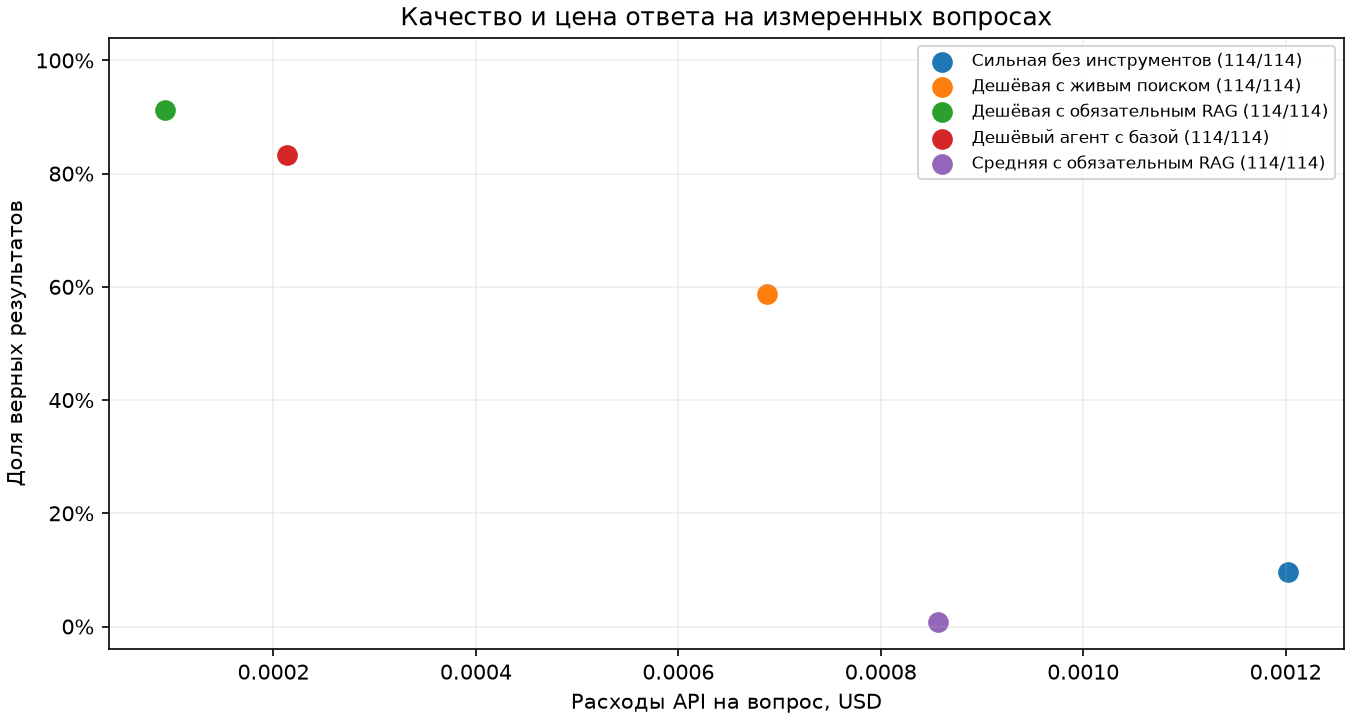

In [3]:
display(Image(filename=str(results_dir / "money_chart.png"), width=850))

## Где агент отказался

У положительных вопросов есть эталонная цитата. У отрицательных сведений для ответа в корпусе недостаточно. Для каждого столбца указан собственный знаменатель. Отказ модели и пустая выдача поиска учитываются отдельно.

In [4]:
rows = []
for name, label in labels.items():
    v = configs[name]
    p, n = v["positive_n"], v["negative_n"]
    rows.append([
        label, ratio(v["correct_answer"], p), ratio(v["correct_refusal"], n),
        ratio(v["false_refusal"], p), ratio(v["no_hits_negative"], n),
        ratio(v["false_refusal"] + v["no_hits_positive"], p),
        f"{v['invalid_output']} / {v['execution_error']}" if v["n"] else "—",
    ])
table(["Режим", "Верные ответы (+)", "Отказы модели (−)", "Ложные отказы модели (+)",
       "Пустая выдача (−)", "Все ложные отказы (+)", "invalid_output / сбой выполнения"], rows)

| Режим | Верные ответы (+) | Отказы модели (−) | Ложные отказы модели (+) | Пустая выдача (−) | Все ложные отказы (+) | invalid_output / сбой выполнения |
| --- | --- | --- | --- | --- | --- | --- |
| Сильная без инструментов | 1/104 | 10/10 | 102/104 | 0/10 | 102/104 | 0 / 0 |
| Дешёвая с живым поиском | 58/104 | 9/10 | 33/104 | 0/10 | 33/104 | 0 / 0 |
| Дешёвая с обязательным RAG | 94/104 | 10/10 | 1/104 | 0/10 | 1/104 | 9 / 0 |
| Дешёвый агент с базой знаний | 85/104 | 10/10 | 6/104 | 0/10 | 6/104 | 0 / 0 |
| Средняя с обязательным RAG | 1/104 | 0/10 | 0/104 | 0/10 | 0/104 | 113 / 0 |

## Стал ли верный ответ дешевле

Сопоставим дешёвую модель с живым поиском и ту же модель с обязательным RAG. Сравнение относится к общим исходным вопросам ДЗ‑1, для которых есть ответ. Новые вопросы об отказах учтены выше. Для каждой пары считаем два изменения: сколько прежних ошибок исправлено и сколько прежде верных ответов потеряно.

In [5]:
live = {r["id"]: r for r in details["cheap_live_search"] if r["answerable"]}
rag = {r["id"]: r for r in details["cheap_rag"] if r["answerable"]}
common = sorted(live.keys() & rag.keys())
if len(common) != report["positive_target"]:
    print(f"Парных измерений пока {len(common)}/{report['positive_target']}. Вывод о цене требует полного сравнения.")
else:
    live_right = {i for i in common if live[i]["outcome"] == "correct_answer"}
    rag_right = {i for i in common if rag[i]["outcome"] == "correct_answer"}
    print(f"Общих вопросов — {len(common)}. Верных ответов с живым поиском — {len(live_right)}, с RAG — {len(rag_right)}.")
    print(f"RAG исправил прежних ошибок — {len(rag_right - live_right)}, потерял прежних верных ответов — {len(live_right - rag_right)}.")
    if all(run[i]["cost_usd"] is not None for run in (live, rag) for i in common) and live_right and rag_right:
        before = sum(live[i]["cost_usd"] for i in common) / len(live_right)
        after = sum(rag[i]["cost_usd"] for i in common) / len(rag_right)
        assert abs(before - configs["cheap_live_search"]["positive_cost_per_correct"]) < 1e-12
        assert abs(after - configs["cheap_rag"]["positive_cost_per_correct"]) < 1e-12
        print(f"Цена верного ответа — ${before:.6f} с живым поиском и ${after:.6f} с RAG.")
        if before:
            print(f"Изменение относительно живого поиска — {(after / before - 1):+.1%}.")
    else:
        print("Для сравнения цены нужны подтверждённые расходы и хотя бы один верный ответ в каждом режиме.")

Общих вопросов — 104. Верных ответов с живым поиском — 58, с RAG — 94.
RAG исправил прежних ошибок — 42, потерял прежних верных ответов — 6.
Цена верного ответа — $0.001182 с живым поиском и $0.000106 с RAG.
Изменение относительно живого поиска — -91.0%.


## Разбор ошибок лучшей конфигурации

Среди полных прогонов отчёт выбирает режим с наибольшей точностью, при равенстве — с меньшей ценой верного результата. Для ошибок на положительных вопросах сравниваются эталонная цитата и фрагменты, которые агент видел до ответа. По одному случаю каждой наблюдавшейся категории показано ниже.

In [6]:
analysis = report["failures"]
categories = {
    "evidence_missing": "В выданных фрагментах нет полной цитаты",
    "answer_failed": "Цитата была в контексте, ответ ошибочен",
    "without_tools": "У режима отсутствует инструмент поиска",
    "context_unavailable": "Контекст попытки недоступен",
}
if not analysis["best_config"]:
    print("Для разбора лучшей конфигурации нужны результаты всех пяти режимов.")
else:
    best = analysis["best_config"]
    print("Лучшая конфигурация —", labels[best])
    if not analysis["examples"]:
        print("На вопросах с ответом ошибок нет.")
    for category, example in analysis["examples"].items():
        print(f"\n{categories[category]}. Случаев — {analysis['counts'][category]}.")
        print(f"{example['id']} · {example['question']}")
        print(f"Ожидалось — {example['expected']}\nПолучено — {example['actual']}")
        print(f"Цитата для проверки — {example['evidence']}\nИсточник — {example['source']}")
        passage = example.get("context")
        if passage:
            print("Фрагмент в контексте —", passage["text"][:600])
            print("Источник фрагмента —", passage.get("url") or "не указан")

Лучшая конфигурация — Дешёвая с обязательным RAG

Цитата была в контексте, ответ ошибочен. Случаев — 9.
fresh-120 · What operation was involved in the United States seizing tankers in January 2026?
Ожидалось — Operation Southern Spear
Получено — unknown
Цитата для проверки — January 7 – The United States seizes two shadow fleet tankers, including one under a Russian flag, in the United States oil blockade during Operation Southern Spear.
Источник — https://en.wikipedia.org/wiki/2026
Фрагмент в контексте — January 7 – The United States seizes two shadow fleet tankers, including one under a Russian flag, in the United States oil blockade during Operation Southern Spear.
Источник фрагмента — https://en.wikipedia.org/wiki/2026

В выданных фрагментах нет полной цитаты. Случаев — 1.
fresh-88 · What was the location of the boat capsizing in Japan in March 2026?
Ожидалось — Henoko, Okinawa Prefecture
Получено — unknown
Цитата для проверки — March 16 – Two boats carrying high school students on